# DSCI 552 Homework 4

Name: Zhisong Han

Github Username: zshan666

USC ID: 5284161601

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    roc_curve,
    roc_auc_score
)
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
import statsmodels.api as sm
from sklearn.naive_bayes import GaussianNB, MultinomialNB

## 1. Time Series Classification Part 1: Feature Creation/Extraction

I reused the feature extraction code from Homework 3 for this homework.

In [2]:
data_path = "../data/AReM"
activities = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]
column_names = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

In [3]:
def read_dataset(file_path):
    rows = []
    with open(file_path, "r") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = line.replace(",", " ").split()
            if len(parts) >= 7:
                rows.append(parts[:7])
    data = pd.DataFrame(
        rows,
        columns=column_names
    ).apply(pd.to_numeric)
    expected_times = np.arange(0, 120000, 250)
    if len(data) < 480:
        data = (
            data.set_index("time")
            .reindex(expected_times)
            .interpolate(method="linear")
            .reset_index()
            .rename(columns={"index": "time"})
        )
    return data

In [4]:
train_files = []
test_files = []
all_files = []
for activity in activities:
    folder_path = os.path.join(data_path, activity)
    files = sorted(
        [f for f in os.listdir(folder_path) if f.endswith(".csv")],
        key=lambda x: int(
            x.replace("dataset", "").replace(".csv", "")
        )
    )
    if activity in ["bending1", "bending2"]:
        test_names = [
            "dataset1.csv",
            "dataset2.csv"
        ]
    else:
        test_names = [
            "dataset1.csv",
            "dataset2.csv",
            "dataset3.csv"
        ]
    for file in files:
        full_path = os.path.join(
            folder_path,
            file
        )
        item = (
            activity,
            file,
            full_path
        )
        all_files.append(item)
        if file in test_names:
            test_files.append(item)
        else:
            train_files.append(item)
print("Training instances:", len(train_files))
print("Testing instances:", len(test_files))

Training instances: 69
Testing instances: 19


### Feature Extraction

In [5]:
def extract_features(data):
    features = {}
    time_series = column_names[1:]
    for i, col in enumerate(time_series, start=1):
        x = data[col]
        features[f"min{i}"] = x.min()
        features[f"max{i}"] = x.max()
        features[f"mean{i}"] = x.mean()
        features[f"median{i}"] = x.median()
        features[f"std{i}"] = x.std()
        features[f"q1_{i}"] = x.quantile(0.25)
        features[f"q3_{i}"] = x.quantile(0.75)
    return features

In [6]:
feature_rows = []
train_keys = {
    (activity, file)
    for activity, file, _ in train_files
}
for activity, file, file_path in all_files:
    data = read_dataset(file_path)
    row = {
        "activity": activity,
        "dataset": file,
        "set": "train" if (activity, file) in train_keys else "test"
    }
    row.update(extract_features(data))
    feature_rows.append(row)
features_df = pd.DataFrame(feature_rows)
print("Shape:", features_df.shape)

Shape: (88, 45)


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### 2(a) Binary Classification Using Logistic Regression

#### 2(a)(i)

I use min, mean, and max from time series 1, 2, and 6 to compare bending with the other activities.

In [7]:
train_df = features_df[
    features_df["set"] == "train"
].copy()
train_df["class"] = train_df["activity"].apply(
    lambda x: "bending"
    if x in ["bending1", "bending2"]
    else "other"
)
selected_features = [
    "min1", "mean1", "max1",
    "min2", "mean2", "max2",
    "min6", "mean6", "max6"
]
print(train_df["class"].value_counts())

class
other      60
bending     9
Name: count, dtype: int64


/opt/anaconda3/lib/python3.14/site-packages/pandas/plotting/_matplotlib/misc.py:99: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(boundaries_list[j])
/opt/anaconda3/lib/python3.14/site-packages/pandas/plotting/_matplotlib/misc.py:100: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(boundaries_list[i])
/opt/anaconda3/lib/python3.14/site-packages/pandas/plotting/_matplotlib/misc.py:90: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(boundaries_list[i])


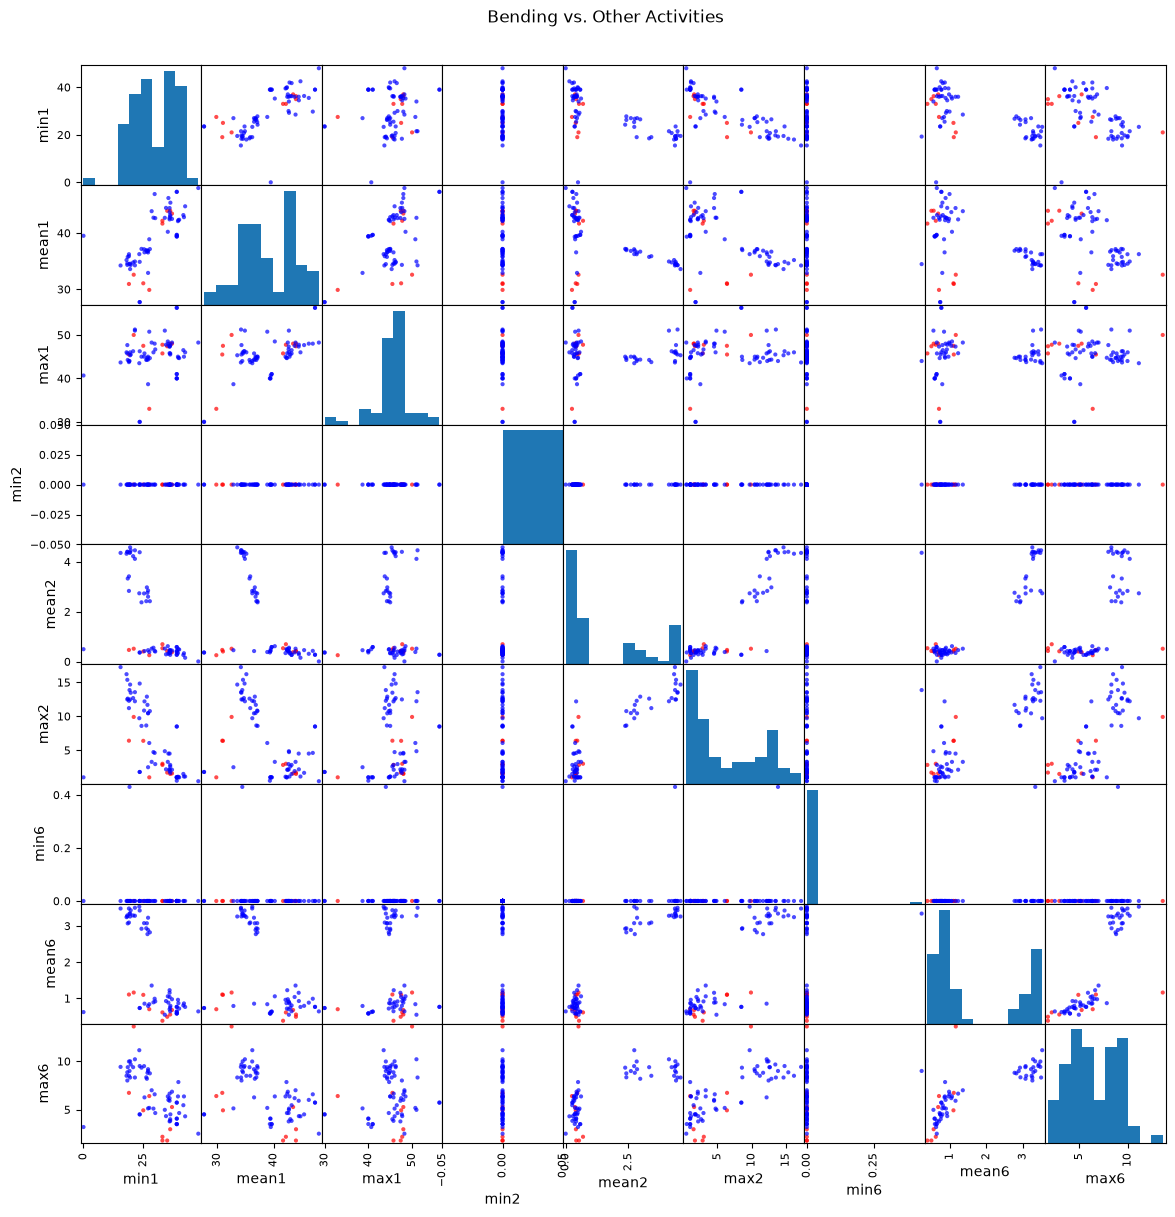

In [8]:
colors = train_df["class"].map({
    "bending": "red",
    "other": "blue"
})
pd.plotting.scatter_matrix(
    train_df[selected_features],
    figsize=(14, 14),
    diagonal="hist",
    c=colors,
    alpha=0.7
)
plt.suptitle(
    "Bending vs. Other Activities",
    y=0.92
)
plt.show()

#### 2(a)(ii)

I split each time series into two equal parts and extract the same features again.

In [9]:
split_rows = []
sensor_cols = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]
for activity, file, file_path in train_files:
    data = read_dataset(file_path)
    row = {
        "activity": activity,
        "class": (
            "bending"
            if activity in ["bending1", "bending2"]
            else "other"
        )
    }
    for i, col in enumerate(sensor_cols, start=1):
        parts = np.array_split(data[col].to_numpy(), 2)
        for j, part in enumerate(parts, start=1):
            row[f"min{i}_{j}"] = np.min(part)
            row[f"mean{i}_{j}"] = np.mean(part)
            row[f"max{i}_{j}"] = np.max(part)
    split_rows.append(row)
split_df = pd.DataFrame(split_rows)
print("Shape:", split_df.shape)

Shape: (69, 38)


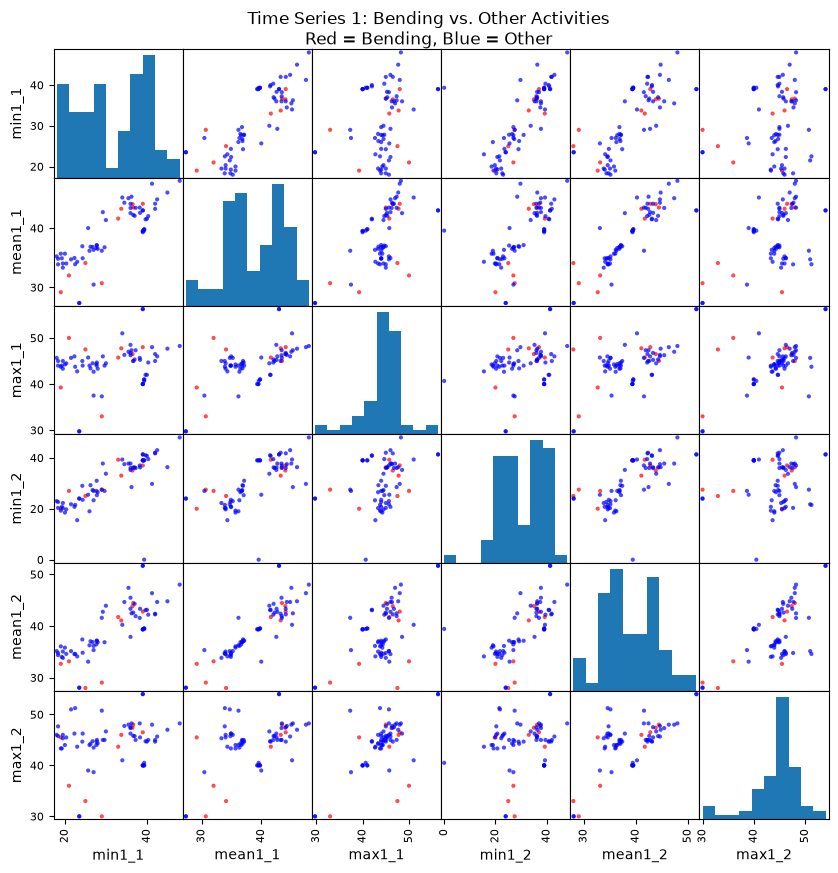

/opt/anaconda3/lib/python3.14/site-packages/pandas/plotting/_matplotlib/misc.py:90: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(boundaries_list[i])
/opt/anaconda3/lib/python3.14/site-packages/pandas/plotting/_matplotlib/misc.py:100: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(boundaries_list[i])
/opt/anaconda3/lib/python3.14/site-packages/pandas/plotting/_matplotlib/misc.py:99: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(boundaries_list[j])
/opt/anaconda3/lib/python3.14/site-packages/pandas/plotting/_matplotlib/misc.py:114: RuntimeWarning: invalid value encountered in divide
  adj = (locs - lim1[0]) / (lim1[1] - lim1[0])


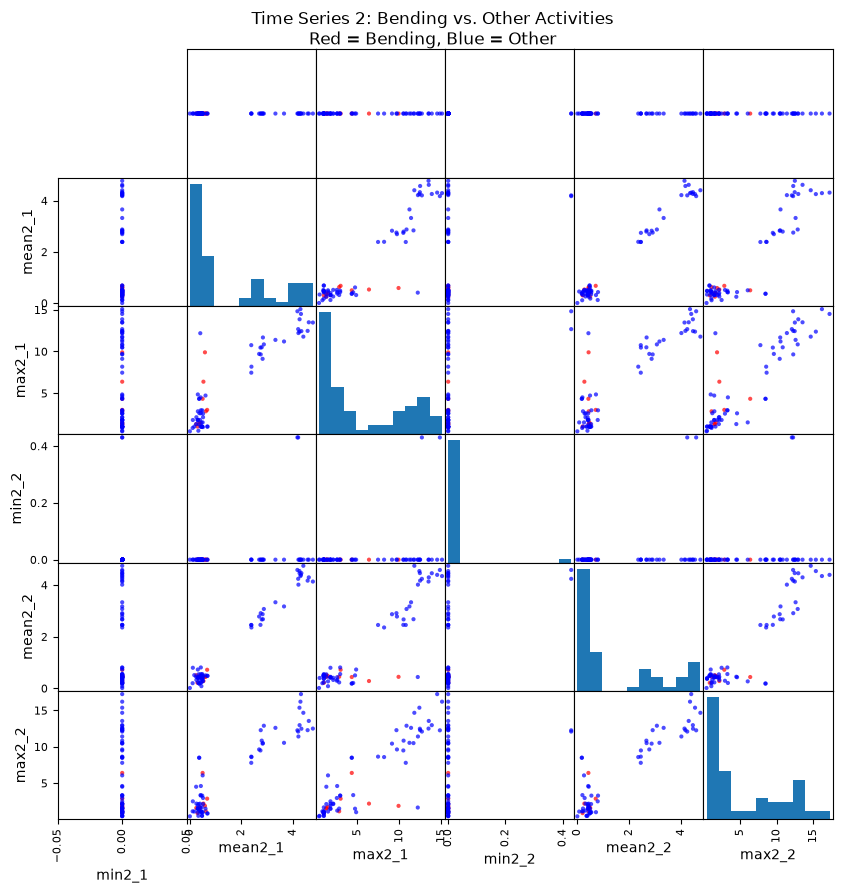

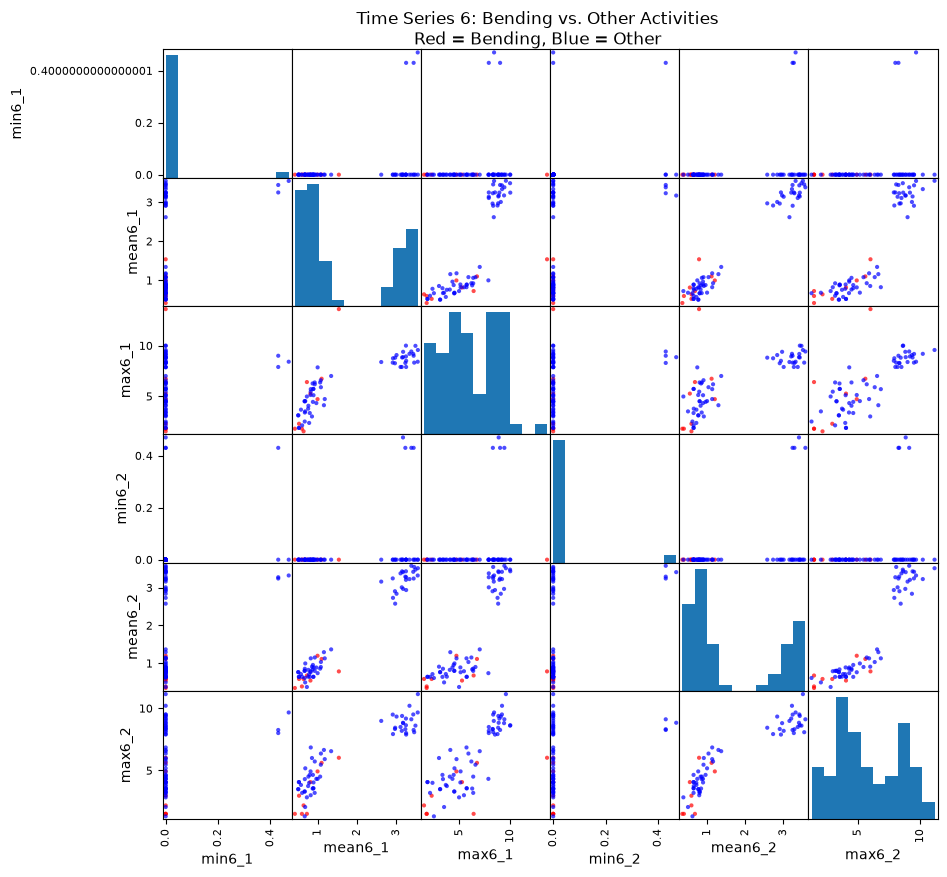

In [10]:
split_colors = split_df["class"].map({
    "bending": "red",
    "other": "blue"
})
for series in [1, 2, 6]:
    cols = [
        f"min{series}_1",
        f"mean{series}_1",
        f"max{series}_1",
        f"min{series}_2",
        f"mean{series}_2",
        f"max{series}_2"
    ]
    pd.plotting.scatter_matrix(
        split_df[cols],
        figsize=(10, 10),
        diagonal="hist",
        c=split_colors,
        alpha=0.7
    )
    plt.suptitle(
        f"Time Series {series}: Bending vs. Other Activities\n"
        "Red = Bending, Blue = Other",
        y=0.92
    )
    plt.show()

There is no considerable difference compared with 2(a)(i). Splitting the time series gives more features, but bending and the other activities still overlap in many plots.

#### 2(a)(iii)

I use 5-fold stratified cross-validation and RFE to find the best values of \(l\) and \(p\).

In [11]:
def build_segment_features(file_list, l):
    rows = []
    labels = []
    for activity, file, file_path in file_list:
        data = read_dataset(file_path)
        row = {}
        for i, col in enumerate(sensor_cols, start=1):
            parts = np.array_split(
                data[col].to_numpy(),
                l
            )
            for j, part in enumerate(parts, start=1):
                row[f"min{i}_{j}"] = np.min(part)
                row[f"max{i}_{j}"] = np.max(part)
                row[f"mean{i}_{j}"] = np.mean(part)
                row[f"median{i}_{j}"] = np.median(part)
                row[f"std{i}_{j}"] = np.std(part, ddof=1)
                row[f"q1_{i}_{j}"] = np.percentile(part, 25)
                row[f"q3_{i}_{j}"] = np.percentile(part, 75)
        rows.append(row)
        labels.append(
            1 if activity in ["bending1", "bending2"] else 0
        )
    X = pd.DataFrame(rows)
    y = np.array(labels)
    return X, y

The right way is to perform feature selection inside each cross-validation fold. Selecting features before cross-validation would cause data leakage.

In [12]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(
        C=1e6,
        solver="liblinear",
        max_iter=5000
    ))
])

In [13]:
cv_results = []
for l in range(1, 21):
    X, y = build_segment_features(train_files, l)
    selector = RFECV(
        estimator=model,
        step=1,
        cv=cv,
        scoring="accuracy",
        min_features_to_select=1,
        importance_getter="named_steps.logreg.coef_",
        n_jobs=-1
    )
    selector.fit(X, y)
    best_p = selector.n_features_
    best_score = selector.cv_results_[
        "mean_test_score"
    ].max()
    cv_results.append({
        "l": l,
        "p": best_p,
        "CV Accuracy": best_score
    })
    print(
        f"l={l:2d}, "
        f"p={best_p:3d}, "
        f"accuracy={best_score:.4f}"
    )
cv_results_df = pd.DataFrame(cv_results)

l= 1, p= 13, accuracy=0.9714
l= 2, p=  3, accuracy=0.9571
l= 3, p=  6, accuracy=0.9286
l= 4, p= 16, accuracy=0.9571
l= 5, p=  4, accuracy=0.9571
l= 6, p=  5, accuracy=0.9857
l= 7, p=  6, accuracy=0.9571
l= 8, p= 61, accuracy=0.9429
l= 9, p=348, accuracy=0.9571
l=10, p= 19, accuracy=0.9714
l=11, p=  4, accuracy=0.9857
l=12, p= 16, accuracy=0.9714
l=13, p=  2, accuracy=0.9857
l=14, p=  1, accuracy=0.9429
l=15, p= 10, accuracy=0.9571
l=16, p=  8, accuracy=0.9429
l=17, p=  1, accuracy=0.9857
l=18, p=  4, accuracy=0.9714
l=19, p=  7, accuracy=0.9857
l=20, p=  2, accuracy=1.0000


In [14]:
best_row = cv_results_df.loc[
    cv_results_df["CV Accuracy"].idxmax()
]
best_l = int(best_row["l"])
best_p = int(best_row["p"])
best_cv_accuracy = best_row["CV Accuracy"]
print("Best l:", best_l)
print("Best p:", best_p)
print("Best CV accuracy:", best_cv_accuracy)

Best l: 20
Best p: 2
Best CV accuracy: 1.0


The best result is \(l=20\) and \(p=2\), with a 5-fold cross-validation accuracy of 1.00.

#### 2(a)(iv)

In [15]:
X_best, y_best = build_segment_features(
    train_files,
    best_l
)
final_selector = RFECV(
    estimator=model,
    step=1,
    cv=cv,
    scoring="accuracy",
    min_features_to_select=1,
    importance_getter="named_steps.logreg.coef_",
    n_jobs=-1
)
final_selector.fit(X_best, y_best)
selected_feature_names = X_best.columns[
    final_selector.support_
].tolist()
X_selected = X_best[
    selected_feature_names
]
print("Number of selected features:",
      len(selected_feature_names))
print("Selected features:",
      selected_feature_names)

Number of selected features: 2
Selected features: ['std3_16', 'q1_5_3']


In [16]:
scaler = StandardScaler()
X_selected_scaled = scaler.fit_transform(X_selected)
final_model = LogisticRegression(
    C=1e6,
    solver="liblinear",
    max_iter=5000
)
final_model.fit(
    X_selected_scaled,
    y_best
)
train_pred = final_model.predict(
    X_selected_scaled
)
train_prob = final_model.predict_proba(
    X_selected_scaled
)[:, 1]
cm = confusion_matrix(
    y_best,
    train_pred
)
train_accuracy = accuracy_score(
    y_best,
    train_pred
)
auc = roc_auc_score(
    y_best,
    train_prob
)
print("Confusion Matrix:")
print(cm)
print("\nTraining Accuracy:",
      train_accuracy)
print("AUC:", auc)

Confusion Matrix:
[[60  0]
 [ 0  9]]

Training Accuracy: 1.0
AUC: 1.0


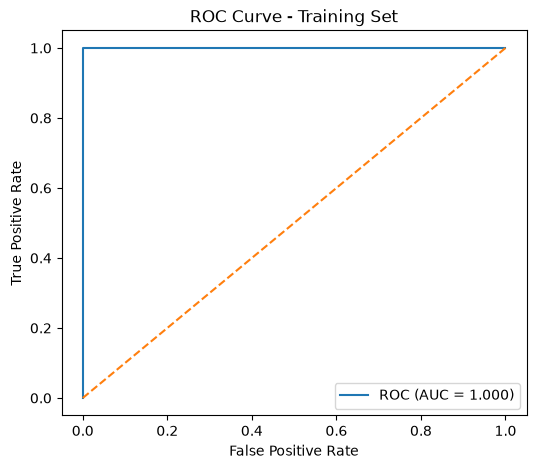

In [17]:
fpr, tpr, _ = roc_curve(
    y_best,
    train_prob
)
plt.figure(figsize=(6, 5))
plt.plot(
    fpr,
    tpr,
    label=f"ROC (AUC = {auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Training Set")
plt.legend()
plt.show()

In [18]:
X_sm = sm.add_constant(
    X_selected_scaled
)
logit_model = sm.Logit(
    y_best,
    X_sm
)
logit_result = logit_model.fit(
    disp=False,
    maxiter=5000
)
coef_table = pd.DataFrame({
    "Feature": [
        "Intercept"
    ] + selected_feature_names,
    "Coefficient": logit_result.params,
    "p-value": logit_result.pvalues
})
coef_table

/opt/anaconda3/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/anaconda3/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/anaconda3/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/anaconda3/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/anaconda3/lib/p

,Feature,Coefficient,p-value
0,Intercept,-367.358533,NaN
1,std3_16,-135.532585,NaN
2,q1_5_3,479.311200,NaN


The training accuracy and AUC are both 1.00. The p-values could not be estimated because the classes are perfectly separated, which also causes unstable coefficients.

#### 2(a)(v)

In [19]:
X_test, y_test = build_segment_features(
    test_files,
    best_l
)
X_test_selected = X_test[
    selected_feature_names
]
X_test_scaled = scaler.transform(
    X_test_selected
)
test_pred = final_model.predict(
    X_test_scaled
)
test_accuracy = accuracy_score(
    y_test,
    test_pred
)
test_cm = confusion_matrix(
    y_test,
    test_pred
)
print("Test Confusion Matrix:")
print(test_cm)
print("\nTest Accuracy:", test_accuracy)
print("CV Accuracy:", best_cv_accuracy)

Test Confusion Matrix:
[[14  1]
 [ 1  3]]

Test Accuracy: 0.8947368421052632
CV Accuracy: 1.0


The test accuracy is about 89.47%, which is lower than the cross-validation accuracy of 100%.

#### 2(a)(vi)

Yes. The classes are very well separated, which causes instability in the logistic regression coefficients and makes the p-values unavailable.

#### 2(a)(vii)

Yes. The training set is imbalanced with 60 other activities and 9 bending activities. I use case-control sampling to balance the classes.

In [20]:
case_idx = np.where(y_best == 1)[0]
control_idx = np.where(y_best == 0)[0]
rng = np.random.default_rng(42)
sampled_control_idx = rng.choice(
    control_idx,
    size=len(case_idx),
    replace=False
)
sample_idx = np.concatenate([
    case_idx,
    sampled_control_idx
])
X_cc = X_selected.iloc[sample_idx]
y_cc = y_best[sample_idx]
print("Case-control class counts:")
print(np.bincount(y_cc))

Case-control class counts:
[9 9]


In [21]:
cc_scaler = StandardScaler()
X_cc_scaled = cc_scaler.fit_transform(X_cc)
cc_model = LogisticRegression(
    C=1e6,
    solver="liblinear",
    max_iter=5000
)
cc_model.fit(
    X_cc_scaled,
    y_cc
)
sampling_fraction_case = 1.0
sampling_fraction_control = 9 / 60
adjustment = np.log(
    sampling_fraction_control /
    sampling_fraction_case
)
adjusted_intercept = (
    cc_model.intercept_[0] + adjustment
)
print("Original intercept:",
      cc_model.intercept_[0])
print("Adjusted intercept:",
      adjusted_intercept)
print("Coefficients:",
      cc_model.coef_[0])

Original intercept: 0.35230279258133496
Adjusted intercept: -1.5448171923045464
Coefficients: [-10.42201021  20.35139272]


In [22]:
X_full_scaled = cc_scaler.transform(
    X_selected
)
log_odds = (
    adjusted_intercept
    + X_full_scaled @ cc_model.coef_[0]
)
cc_prob = 1 / (
    1 + np.exp(-log_odds)
)
cc_pred = (
    cc_prob >= 0.5
).astype(int)
cc_cm = confusion_matrix(
    y_best,
    cc_pred
)
cc_accuracy = accuracy_score(
    y_best,
    cc_pred
)
cc_auc = roc_auc_score(
    y_best,
    cc_prob
)
print("Confusion Matrix:")
print(cc_cm)
print("\nAccuracy:", cc_accuracy)
print("AUC:", cc_auc)

Confusion Matrix:
[[60  0]
 [ 0  9]]

Accuracy: 1.0
AUC: 1.0


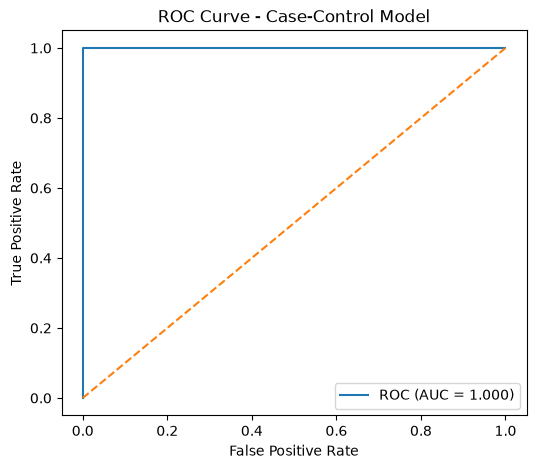

In [23]:
cc_fpr, cc_tpr, _ = roc_curve(
    y_best,
    cc_prob
)
plt.figure(figsize=(6, 5))
plt.plot(
    cc_fpr,
    cc_tpr,
    label=f"ROC (AUC = {cc_auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Case-Control Model")
plt.legend()
plt.show()

After case-control sampling, the two classes are balanced. The adjusted model still gives an accuracy and AUC of 1.00 on the training set.

### 2(b) Binary Classification Using L1-Penalized Logistic Regression

#### 2(b)(i)

I use 5-fold cross-validation to select both \(l\) and \(C\) for L1-penalized logistic regression.

In [24]:
C_values = np.logspace(-4, 4, 9)
l1_results = []
for l in range(1, 21):
    X, y = build_segment_features(
        train_files,
        l
    )
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(
            l1_ratio=1,
            solver="liblinear",
            max_iter=5000
        ))
    ])
    grid = GridSearchCV(
        pipeline,
        param_grid={
            "logreg__C": C_values
        },
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )
    grid.fit(X, y)
    best_model = grid.best_estimator_
    coefficients = (
        best_model
        .named_steps["logreg"]
        .coef_[0]
    )
    nonzero_features = np.sum(
        coefficients != 0
    )
    l1_results.append({
        "l": l,
        "C": grid.best_params_["logreg__C"],
        "Selected Features": nonzero_features,
        "CV Accuracy": grid.best_score_
    })
    print(
        f"l={l:2d}, "
        f"C={grid.best_params_['logreg__C']:.4g}, "
        f"features={nonzero_features:3d}, "
        f"accuracy={grid.best_score_:.4f}"
    )
l1_results_df = pd.DataFrame(
    l1_results
)

l= 1, C=1e+04, features= 37, accuracy=0.9714
l= 2, C=1, features=  8, accuracy=0.9571
l= 3, C=1, features=  8, accuracy=0.9571
l= 4, C=1, features= 10, accuracy=0.9571
l= 5, C=100, features= 24, accuracy=0.9418
l= 6, C=100, features= 24, accuracy=0.9571
l= 7, C=1, features= 11, accuracy=0.9275
l= 8, C=1000, features= 74, accuracy=0.9429
l= 9, C=1, features= 13, accuracy=0.9275
l=10, C=100, features= 32, accuracy=0.9714
l=11, C=1, features=  8, accuracy=0.9714
l=12, C=1, features=  9, accuracy=0.9714
l=13, C=1, features= 11, accuracy=0.9714
l=14, C=1, features= 12, accuracy=0.9714
l=15, C=1, features= 14, accuracy=0.9418
l=16, C=10, features= 23, accuracy=0.9429
l=17, C=100, features= 47, accuracy=0.9571
l=18, C=1, features=  8, accuracy=0.9714
l=19, C=1, features= 10, accuracy=0.9857
l=20, C=1, features= 10, accuracy=0.9714


In [25]:
best_l1_row = l1_results_df.loc[
    l1_results_df["CV Accuracy"].idxmax()
]
best_l_l1 = int(best_l1_row["l"])
best_C_l1 = best_l1_row["C"]
best_l1_accuracy = best_l1_row["CV Accuracy"]
print("Best l:", best_l_l1)
print("Best C:", best_C_l1)
print(
    "Best CV accuracy:",
    best_l1_accuracy
)

Best l: 19
Best C: 1.0
Best CV accuracy: 0.9857142857142858


The best result is \(l=19\) and \(C=1.0\), with a cross-validation accuracy of about 98.57%.

#### 2(b)(ii)

The previous feature selection method performs slightly better, with a CV accuracy of 1.00 compared with 0.9857 for L1 logistic regression. However, L1 regularization is easier to implement because feature selection is done directly by the model.

### 2(c) Multi-class Classification

#### 2(c)(i)

I use L1-penalized logistic regression to classify all seven activities.

In [26]:
def build_multiclass_features(file_list, l):
    rows = []
    labels = []
    for activity, file, file_path in file_list:
        data = read_dataset(file_path)
        row = {}
        for i, col in enumerate(sensor_cols, start=1):
            parts = np.array_split(
                data[col].to_numpy(),
                l
            )
            for j, part in enumerate(parts, start=1):
                row[f"min{i}_{j}"] = np.min(part)
                row[f"max{i}_{j}"] = np.max(part)
                row[f"mean{i}_{j}"] = np.mean(part)
                row[f"median{i}_{j}"] = np.median(part)
                row[f"std{i}_{j}"] = np.std(part, ddof=1)
                row[f"q1_{i}_{j}"] = np.percentile(part, 25)
                row[f"q3_{i}_{j}"] = np.percentile(part, 75)
        rows.append(row)
        labels.append(activity)
    X = pd.DataFrame(rows)
    y = np.array(labels)
    return X, y

In [27]:
X_multi, y_multi = build_multiclass_features(
    train_files,
    1
)
print("Shape:", X_multi.shape)
print("\nClass counts:")
print(pd.Series(y_multi).value_counts())

Shape: (69, 42)

Class counts:
cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64


Because bending2 only has 4 training instances, I use 4-fold stratified cross-validation for the multiclass model.

In [28]:
multi_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)
multi_results = []
for l in range(1, 21):
    X, y = build_multiclass_features(
        train_files,
        l
    )
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(
            l1_ratio=1,
            solver="saga",
            max_iter=10000,
            random_state=42
        ))
    ])
    grid = GridSearchCV(
        pipeline,
        param_grid={
            "logreg__C": C_values
        },
        cv=multi_cv,
        scoring="accuracy",
        n_jobs=-1
    )
    grid.fit(X, y)
    multi_results.append({
        "l": l,
        "C": grid.best_params_["logreg__C"],
        "CV Accuracy": grid.best_score_
    })
    print(
        f"l={l:2d}, "
        f"C={grid.best_params_['logreg__C']:.4g}, "
        f"accuracy={grid.best_score_:.4f}"
    )
multi_results_df = pd.DataFrame(
    multi_results
)

l= 1, C=1, accuracy=0.8701
l= 2, C=1000, accuracy=0.9273
l= 3, C=1000, accuracy=0.8987
l= 4, C=1000, accuracy=0.8840
l= 5, C=1e+04, accuracy=0.9134
l= 6, C=1e+04, accuracy=0.9134
l= 7, C=1000, accuracy=0.8840
l= 8, C=1000, accuracy=0.8407
l= 9, C=1000, accuracy=0.8840
l=10, C=1000, accuracy=0.8260
l=11, C=100, accuracy=0.8407
l=12, C=1000, accuracy=0.8554
l=13, C=1000, accuracy=0.8407
l=14, C=1000, accuracy=0.8113
l=15, C=10, accuracy=0.8399
l=16, C=1000, accuracy=0.7966
l=17, C=1, accuracy=0.8407
l=18, C=1, accuracy=0.8554
l=19, C=1000, accuracy=0.8260
l=20, C=10, accuracy=0.8546


In [29]:
best_multi_row = multi_results_df.loc[
    multi_results_df["CV Accuracy"].idxmax()
]
best_multi_l = int(best_multi_row["l"])
best_multi_C = best_multi_row["C"]
best_multi_cv_accuracy = best_multi_row["CV Accuracy"]
print("Best l:", best_multi_l)
print("Best C:", best_multi_C)
print(
    "Best CV accuracy:",
    best_multi_cv_accuracy
)

Best l: 2
Best C: 1000.0
Best CV accuracy: 0.9272875816993464


The best result is \(l=2\) and \(C=1000\), with a cross-validation accuracy of about 92.73%.

In [30]:
X_multi_train, y_multi_train = build_multiclass_features(
    train_files,
    best_multi_l
)
X_multi_test, y_multi_test = build_multiclass_features(
    test_files,
    best_multi_l
)
final_multi_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(
        l1_ratio=1,
        solver="saga",
        C=best_multi_C,
        max_iter=10000,
        random_state=42
    ))
])
final_multi_model.fit(
    X_multi_train,
    y_multi_train
)
multi_test_pred = final_multi_model.predict(
    X_multi_test
)
multi_test_prob = final_multi_model.predict_proba(
    X_multi_test
)
multi_test_accuracy = accuracy_score(
    y_multi_test,
    multi_test_pred
)
multi_test_error = 1 - multi_test_accuracy
print("Test Accuracy:", multi_test_accuracy)
print("Test Error:", multi_test_error)

Test Accuracy: 0.8421052631578947
Test Error: 0.1578947368421053


In [31]:
class_names = final_multi_model.named_steps[
    "logreg"
].classes_
multi_cm = confusion_matrix(
    y_multi_test,
    multi_test_pred,
    labels=class_names
)
multi_cm_df = pd.DataFrame(
    multi_cm,
    index=class_names,
    columns=class_names
)
multi_cm_df

,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,1,0,0,0,1,1,0
standing,0,0,0,0,0,3,0
walking,0,0,0,0,0,0,3


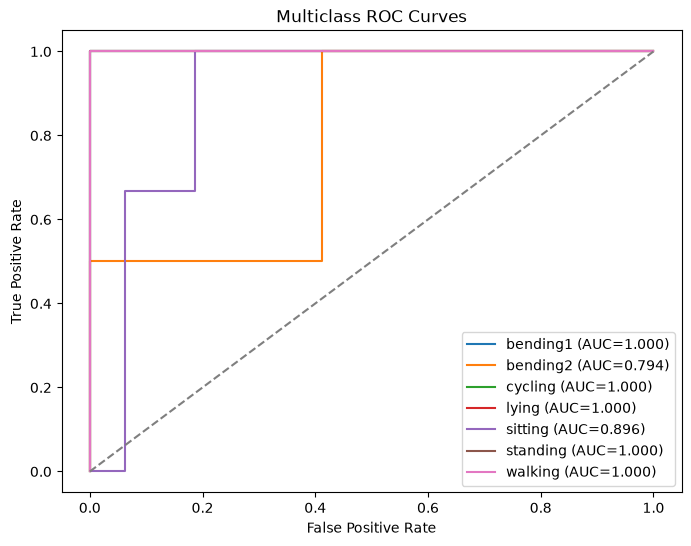

In [32]:
y_multi_test_bin = label_binarize(
    y_multi_test,
    classes=class_names
)
plt.figure(figsize=(8, 6))
for i, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(
        y_multi_test_bin[:, i],
        multi_test_prob[:, i]
    )
    class_auc = roc_auc_score(
        y_multi_test_bin[:, i],
        multi_test_prob[:, i]
    )
    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC={class_auc:.3f})"
    )
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves")
plt.legend()
plt.show()

In [33]:
macro_auc = roc_auc_score(
    y_multi_test_bin,
    multi_test_prob,
    average="macro",
    multi_class="ovr"
)
print("Macro-average AUC:", macro_auc)

Macro-average AUC: 0.9557072829131652


The test error is about 15.79%, and the macro-average AUC is about 0.956. Most activities are classified correctly, but there are a few mistakes for bending2 and sitting.

#### 2(c)(ii)

I compare Gaussian Naive Bayes and Multinomial Naive Bayes using cross-validation.

In [34]:
nb_results = []
for l in range(1, 21):
    X, y = build_multiclass_features(
        train_files,
        l
    )
    gaussian_scores = cross_val_score(
        GaussianNB(),
        X,
        y,
        cv=multi_cv,
        scoring="accuracy"
    )
    multinomial_scores = cross_val_score(
        MultinomialNB(),
        X,
        y,
        cv=multi_cv,
        scoring="accuracy"
    )
    nb_results.append({
        "l": l,
        "Gaussian CV Accuracy": gaussian_scores.mean(),
        "Multinomial CV Accuracy": multinomial_scores.mean()
    })
nb_results_df = pd.DataFrame(nb_results)
nb_results_df

,l,Gaussian CV Accuracy,Multinomial CV Accuracy
0,1,0.841503,0.870915
1,2,0.825980,0.826797
2,3,0.697712,0.825980
3,4,0.680556,0.796569
4,5,0.637255,0.795752
5,6,0.651961,0.781863
6,7,0.624183,0.868464
7,8,0.638072,0.810458
8,9,0.566176,0.797386
9,10,0.622549,0.781863


In [35]:
best_gaussian_row = nb_results_df.loc[
    nb_results_df["Gaussian CV Accuracy"].idxmax()
]
best_multinomial_row = nb_results_df.loc[
    nb_results_df["Multinomial CV Accuracy"].idxmax()
]
best_gaussian_l = int(best_gaussian_row["l"])
best_multinomial_l = int(best_multinomial_row["l"])
print("Gaussian NB")
print("Best l:", best_gaussian_l)
print(
    "Best CV accuracy:",
    best_gaussian_row["Gaussian CV Accuracy"]
)
print("\nMultinomial NB")
print("Best l:", best_multinomial_l)
print(
    "Best CV accuracy:",
    best_multinomial_row["Multinomial CV Accuracy"]
)

Gaussian NB
Best l: 1
Best CV accuracy: 0.8415032679738563

Multinomial NB
Best l: 1
Best CV accuracy: 0.8709150326797386


In [36]:
X_g_train, y_g_train = build_multiclass_features(
    train_files,
    best_gaussian_l
)
X_g_test, y_g_test = build_multiclass_features(
    test_files,
    best_gaussian_l
)
gaussian_model = GaussianNB()
gaussian_model.fit(
    X_g_train,
    y_g_train
)
gaussian_pred = gaussian_model.predict(
    X_g_test
)
gaussian_prob = gaussian_model.predict_proba(
    X_g_test
)
gaussian_accuracy = accuracy_score(
    y_g_test,
    gaussian_pred
)
gaussian_error = 1 - gaussian_accuracy
print("Gaussian NB Test Accuracy:", gaussian_accuracy)
print("Gaussian NB Test Error:", gaussian_error)

Gaussian NB Test Accuracy: 0.8947368421052632
Gaussian NB Test Error: 0.10526315789473684


In [37]:
X_m_train, y_m_train = build_multiclass_features(
    train_files,
    best_multinomial_l
)
X_m_test, y_m_test = build_multiclass_features(
    test_files,
    best_multinomial_l
)
multinomial_model = MultinomialNB()
multinomial_model.fit(
    X_m_train,
    y_m_train
)
multinomial_pred = multinomial_model.predict(
    X_m_test
)
multinomial_prob = multinomial_model.predict_proba(
    X_m_test
)
multinomial_accuracy = accuracy_score(
    y_m_test,
    multinomial_pred
)
multinomial_error = 1 - multinomial_accuracy
print(
    "Multinomial NB Test Accuracy:",
    multinomial_accuracy
)
print(
    "Multinomial NB Test Error:",
    multinomial_error
)

Multinomial NB Test Accuracy: 0.8947368421052632
Multinomial NB Test Error: 0.10526315789473684


In [38]:
nb_class_names = gaussian_model.classes_
gaussian_cm = confusion_matrix(
    y_g_test,
    gaussian_pred,
    labels=nb_class_names
)
multinomial_cm = confusion_matrix(
    y_m_test,
    multinomial_pred,
    labels=nb_class_names
)
print("Gaussian NB Confusion Matrix:")
display(
    pd.DataFrame(
        gaussian_cm,
        index=nb_class_names,
        columns=nb_class_names
    )
)
print("Multinomial NB Confusion Matrix:")
display(
    pd.DataFrame(
        multinomial_cm,
        index=nb_class_names,
        columns=nb_class_names
    )
)

Gaussian NB Confusion Matrix:


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,2,0,0,0,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,2,1,0,0
sitting,0,0,0,0,3,0,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


Multinomial NB Confusion Matrix:


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,2,0,0,0,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,0,0,0,0,2,1,0
standing,0,0,0,1,0,2,0
walking,0,0,0,0,0,0,3


In [39]:
y_nb_test_bin = label_binarize(
    y_g_test,
    classes=nb_class_names
)
gaussian_auc = roc_auc_score(
    y_nb_test_bin,
    gaussian_prob,
    average="macro",
    multi_class="ovr"
)
multinomial_auc = roc_auc_score(
    y_nb_test_bin,
    multinomial_prob,
    average="macro",
    multi_class="ovr"
)
print("Gaussian NB Macro AUC:", gaussian_auc)
print("Multinomial NB Macro AUC:", multinomial_auc)

Gaussian NB Macro AUC: 0.9642857142857143
Multinomial NB Macro AUC: 0.9851190476190476


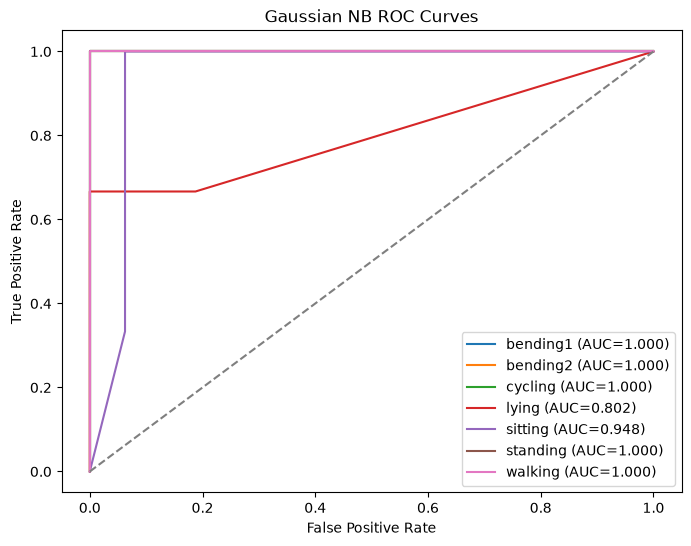

In [40]:
plt.figure(figsize=(8, 6))
for i, class_name in enumerate(nb_class_names):
    fpr, tpr, _ = roc_curve(
        y_nb_test_bin[:, i],
        gaussian_prob[:, i]
    )
    class_auc = roc_auc_score(
        y_nb_test_bin[:, i],
        gaussian_prob[:, i]
    )
    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC={class_auc:.3f})"
    )
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Gaussian NB ROC Curves")
plt.legend()
plt.show()

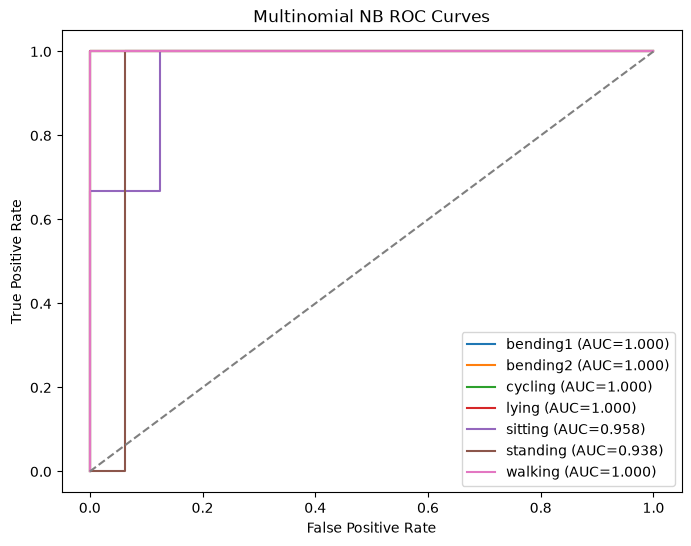

In [41]:
plt.figure(figsize=(8, 6))
for i, class_name in enumerate(nb_class_names):
    fpr, tpr, _ = roc_curve(
        y_nb_test_bin[:, i],
        multinomial_prob[:, i]
    )
    class_auc = roc_auc_score(
        y_nb_test_bin[:, i],
        multinomial_prob[:, i]
    )
    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC={class_auc:.3f})"
    )
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multinomial NB ROC Curves")
plt.legend()
plt.show()

Gaussian NB and Multinomial NB have the same test accuracy of about 89.47%. Multinomial NB has a higher macro-average AUC, so it performs slightly better.

#### 2(c)(iii)

Multinomial Naive Bayes performs best in this problem. It has the highest macro-average AUC and also has a higher test accuracy than the L1 logistic regression model.

## 3. ISLR 4.8.3

For class $k$,

$$
X \sim N(\mu_k, \sigma_k^2)
$$

so the Bayes classifier uses

$$
\delta_k(x)
=
-\frac{1}{2}\log(\sigma_k^2)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
+\log(\pi_k).
$$

Expanding the squared term,

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\frac{1}{2}\log(\sigma_k^2)
+\log(\pi_k).
$$

Since the coefficient of $x^2$ depends on $\sigma_k^2$, it can be different for different classes. Therefore, the decision boundary contains an $x^2$ term.

So the Bayes classifier is quadratic, not linear.

## 4. ISLR 4.8.7

We have

$$
P(Y=\text{Yes})=0.8,
\qquad
P(Y=\text{No})=0.2.
$$

Also,

$$
X\mid Y=\text{Yes}\sim N(10,36),
$$

and

$$
X\mid Y=\text{No}\sim N(0,36).
$$

For \(X=4\),

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{0.8f_{\text{Yes}}(4)}
{0.8f_{\text{Yes}}(4)+0.2f_{\text{No}}(4)}.
$$

Since both classes have the same variance, the common normal density constant cancels:

$$
=
\frac{
0.8e^{-(4-10)^2/(2\cdot36)}
}{
0.8e^{-(4-10)^2/(2\cdot36)}
+
0.2e^{-(4-0)^2/(2\cdot36)}
}.
$$

Therefore,

$$
P(Y=\text{Yes}\mid X=4)
\approx 0.752.
$$

So the probability that the company will issue a dividend is about **75.2%**.